# Response curves for your channels: plug in your own data

**Audience:** analysts who want the return on each marketing channel from their own weekly data. No VECM background is needed. Guides 01 to 05 explain each step in depth.

**How to use it.** Edit the configuration cell below and run every cell. Nothing else needs changing. Every step records a check in a table that is printed at the end with a decision log you can keep.

**Learning objectives.** By the end you will be able to:

- **§1** Get weekly data into the shape the model needs: logs for sales and brand metrics, raw spend for channels with diminishing returns.
- **§2** Run the checks before fitting and know which ones need a decision from you.
- **§3** Fit one model with carryover, diminishing returns and a same-week link, and check the sampler.
- **§4** Read each channel's carryover, saturation and return per £ at current spend.
- **§5** Draw a response curve in £ for each channel and see where the data ends.
- **§6** Keep a record of every check and choice for the write-up.

**By default it runs on simulated data** with all three features in the truth, so the answers can be checked against the values that generated the data. Set `DATA_PATH` to your file to switch.

**Method.** The model follows Cain (2022), *Modelling short- and long-term marketing effects in the consumer purchase journey*, International Journal of Research in Marketing 39(1), 96-116. The README lists his other papers.

In [1]:
# ════════════════════════════════════════════════════════════════════════════
# CONFIGURATION: the only cell to edit
# ════════════════════════════════════════════════════════════════════════════
# A CSV with one row per week. None runs on simulated data with a known answer.
DATA_PATH = None
DATE_COLUMN = "week"

# Sales in £ a week: base sales, or total sales (see guides 06 and 07).
SALES = "organic_sales"
# Brand metrics from the tracker, in funnel order (top of the funnel first).
BRAND_METRICS = ["brand_awareness", "brand_consideration"]

# Marketing channels and the £ cost of one unit of each column.
# Put spend in £1,000s (cost 1_000) and reach in 100,000s. Use None when a
# unit has no £ cost: the return is then reported per unit.
CHANNELS = {
    "brand_spend": 1_000.0,
    "pr_reach": None,
    "sponsorship_reach": None,
}
# Other drivers set outside the brand system: prices, macro, distribution.
OTHER_DRIVERS = ["interest_rate", "consumer_confidence"]

# Options (guide 03 and guide 04). Leave a list empty to switch an option off.
ADSTOCK = list(CHANNELS)  # effect carries over for weeks
SATURATION = list(CHANNELS)  # each extra £ buys a bit less; needs raw spend
# Same-week links between brand metrics, and the drivers that reach each
# effect only through its cause. Ask the exclusion question for every driver
# listed: "could this change consideration other than by building awareness?"
LINKS = {"brand_consideration": ["brand_awareness"]}
EXCLUDED = {"brand_consideration": list(CHANNELS)}

# Lags and rank. None lets the tests choose; check the rank against the funnel.
K_AR_DIFF = None
COINT_RANK = None

FINAL_RUN = False  # True for 4 chains of 2,000 draws before reporting
SEED = 1
# ════════════════════════════════════════════════════════════════════════════

In [2]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bayesian_vecm import (
    BayesianVECM,
    check_stationarity,
    granger_pretest,
    select_coint_rank,
    simulate_brand_data,
)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 140)

DRAWS, TUNE, CHAINS = (2000, 1000, 4) if FINAL_RUN else (1000, 1000, 2)
LEVEL = 0.90  # every interval is a 90% interval
TAILS = (100 * (1 - LEVEL) / 2, 100 * (1 + LEVEL) / 2)
SIMULATED = DATA_PATH is None
CHECKS = []


def check(step, item, result, status, action=""):
    """Record one check. status is "ok", "look" or "decide"."""
    CHECKS.append(
        {"step": step, "check": item, "result": result, "status": status, "action": action}
    )
    flag = {"ok": "ok    ", "look": "LOOK  ", "decide": "DECIDE"}[status]
    print(f"[{flag}] {item}: {result}" + (f"  ->  {action}" if action else ""))


def interval(x, fmt="{:.2f}"):
    lo, hi = np.percentile(x, TAILS)
    return f"{fmt.format(np.median(x))} ({fmt.format(lo)} to {fmt.format(hi)})"

## §1 Load and prepare the data

**Objective:** get weekly data into the shape the model needs.

What the cell below does to each group of columns:

- **Sales and brand metrics:** natural logs. Effects then read as % changes and the long-run ties as ratios.
- **Channels with saturation:** raw spend, never below zero. The curve needs real spend levels.
- **Other channels:** deviation from their average, so 0 means a normal week.
- **Other drivers:** deviation from their average. A driver that trends (a policy rate) enters as its weekly change, chosen by the test in §2.

The simulated brand has carryover (decays 0.5, 0.3 and 0.6), saturation and a same-week link from awareness to consideration of 0.2. Its interest rate is a random walk, so the trending-driver rule gets exercised too.

In [3]:
if SIMULATED:
    DECAYS = {"brand_spend": 0.5, "pr_reach": 0.3, "sponsorship_reach": 0.6}
    LAMBDAS = {"brand_spend": 5.0, "pr_reach": 3.0, "sponsorship_reach": 5.0}
    sim = simulate_brand_data(
        exog_unit_root=("interest_rate",),
        exog_adstock=DECAYS,
        exog_saturation=LAMBDAS,
        contemporaneous={"brand_consideration": {"brand_awareness": 0.2}},
    )
    truth = sim.truth
    # Back to what a data file holds: levels, not logs.
    raw = pd.concat([np.exp(sim.endog), sim.exog], axis=1)
else:
    raw = pd.read_csv(DATA_PATH, index_col=DATE_COLUMN, parse_dates=True).sort_index()

channels = list(CHANNELS)
drivers = channels + OTHER_DRIVERS
endog_cols = [SALES, *BRAND_METRICS]
missing = [c for c in endog_cols + drivers if c not in raw.columns]
if missing:
    raise KeyError(f"Columns not in the data: {missing}")
raw = raw[endog_cols + drivers].astype(float)

check(
    "data",
    "weeks of data",
    f"{len(raw)} weeks",
    "ok" if len(raw) >= 208 else "look",
    "" if len(raw) >= 208 else "under four years: fit the neighbouring rank too",
)
gaps = int(raw.isna().sum().sum())
check(
    "data",
    "missing values",
    f"{gaps}",
    "ok" if gaps == 0 else "decide",
    "" if gaps == 0 else "interpolate short gaps and note them, or shorten the sample",
)
raw = raw.interpolate(limit_direction="both")
negative = [c for c in SATURATION if (raw[c] < 0).any()]
if negative:
    raise ValueError(f"Saturated channels need raw, non-negative spend: {negative}")

endog = np.log(raw[endog_cols])
exog = raw[drivers].copy()
not_saturated = [c for c in drivers if c not in SATURATION]
spend_mean = raw[channels].mean()

print(f"\n{endog.index[0].date()} to {endog.index[-1].date()}, {len(endog)} weeks")
print(raw.describe().T[["mean", "min", "max"]].round(2))

[ok    ] weeks of data: 260 weeks
[ok    ] missing values: 0

2021-01-04 to 2025-12-22, 260 weeks
                        mean     min      max
organic_sales        1457.06  948.97  2239.90
brand_awareness        27.79   18.82    38.72
brand_consideration    13.42    9.75    18.83
brand_spend             0.98    0.42     2.23
pr_reach                1.05    0.50     2.38
sponsorship_reach       0.96    0.39     2.37
interest_rate          -1.33   -4.05     0.96
consumer_confidence    -0.00   -1.22     1.14


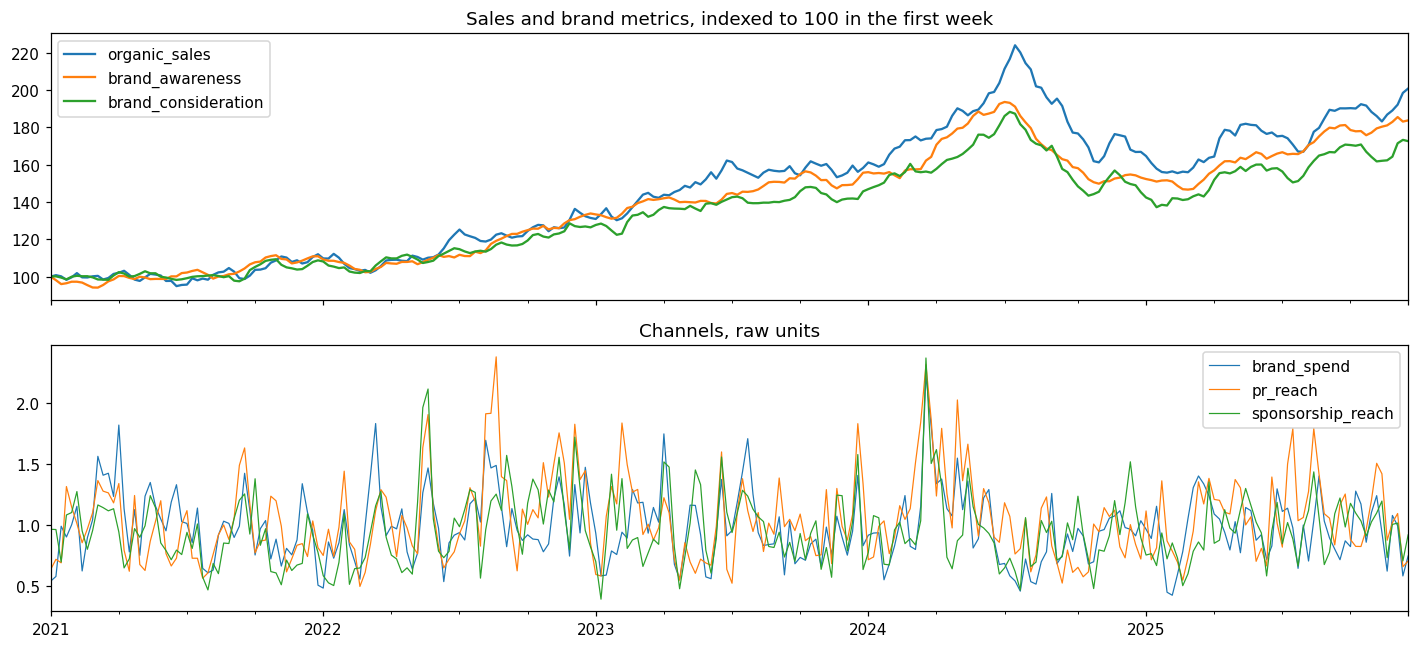

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
(np.exp(endog) / np.exp(endog.iloc[0]) * 100).plot(ax=axes[0])
axes[0].set_title("Sales and brand metrics, indexed to 100 in the first week")
raw[channels].plot(ax=axes[1], lw=0.8)
axes[1].set_title("Channels, raw units")
plt.tight_layout()
plt.show()

## §2 Checks before fitting

**Objective:** run the checks before fitting and know which ones need a decision from you.

- **Trends.** Sales and brand metrics should trend (I(1)) to share long-run ties. A driver that trends enters as its weekly change.
- **What helps predict what** (`granger_pretest`). The feedback rows ask whether past brand metrics predict spend: if budgets follow performance, the channel's effect is biased. One hit in a large table can be chance (3% to 10% per test on simulated data). Ask how that budget is set.
- **The same-week link.** Its instruments must be strong (first-stage F above 10) and agree (Sargan). Otherwise the link is left out, which is safe for the return per £.
- **Lags** from the Hannan-Quinn criterion. **Rank** from the Johansen test, checked against the funnel: K series sharing one trend give K - 1 ties.

In [5]:
station = check_stationarity(pd.concat([endog, exog[OTHER_DRIVERS]], axis=1))
print(station, "\n")
for col in endog_cols:
    trending = col in station.endog
    check(
        "before fit",
        f"{col} trends",
        "yes" if trending else "no",
        "ok" if trending else "decide",
        ""
        if trending
        else "a series with no trend cannot share a long-run tie: move it to drivers?",
    )

trending_drivers = [c for c in OTHER_DRIVERS if c in station.endog]
for col in trending_drivers:
    check("before fit", f"{col} trends", "yes", "ok", "entered as its weekly change")
exog[trending_drivers] = exog[trending_drivers].diff()
exog[not_saturated] = exog[not_saturated] - exog[not_saturated].mean()
exog = exog.iloc[1:]
endog = endog.iloc[1:]

Stationarity check (ADF test, 5% level)
  regression = 'c'

  variable             p (levels)   p (diff)  order  verdict
  -----------------------------------------------------------------------------------------------
  organic_sales             0.817      0.000   I(1)  trending: endog, or exog after .diff()
  brand_awareness           0.685      0.000   I(1)  trending: endog, or exog after .diff()
  brand_consideration       0.744      0.000   I(1)  trending: endog, or exog after .diff()
  interest_rate             0.578      0.000   I(1)  trending: endog, or exog after .diff()
  consumer_confidence       0.000      0.000   I(0)  stationary: use as exog 

[ok    ] organic_sales trends: yes
[ok    ] brand_awareness trends: yes
[ok    ] brand_consideration trends: yes
[ok    ] interest_rate trends: yes  ->  entered as its weekly change


In [6]:
links = {k: v for k, v in LINKS.items() if v}
pretest = granger_pretest(
    endog, exog, contemporaneous=links or None, excluded=EXCLUDED if links else None
)
print(pretest)

alpha = pretest.alpha
feedback = pretest.tests[
    (pretest.tests["group"] == "metric -> driver")
    & pretest.tests["cause"].isin(endog_cols)
    & pretest.tests["effect"].isin(channels)
    & (pretest.tests["p_value"] < alpha)
]
if feedback.empty:
    check("before fit", "budgets follow performance", "no feedback found", "ok")
for r in feedback.itertuples():
    check(
        "before fit",
        f"feedback {r.cause} -> {r.effect}",
        f"p = {r.p_value:.3f}",
        "decide",
        "ask how this budget is set; one hit in a large table can be chance",
    )

LINKS_USED, EXCLUDED_USED = {}, {}
if links:
    for r in pretest.same_week.itertuples():
        keep = r.verdict in ("same-week link", "no clear evidence")
        check(
            "before fit",
            f"same-week {r.cause} -> {r.effect}",
            f"{r.verdict}, 2SLS {r.estimate:.2f}, F {r.first_stage_f:.0f}, "
            f"Sargan p {r.sargan_p:.2f}",
            "ok" if keep else "look",
            "kept" if keep else "left out of the fit",
        )
        if keep:
            LINKS_USED.setdefault(r.effect, []).append(r.cause)
    EXCLUDED_USED = {k: v for k, v in EXCLUDED.items() if k in LINKS_USED}
    for effect, drop in EXCLUDED_USED.items():
        check(
            "before fit",
            f"exclusions for {effect}",
            ", ".join(drop),
            "decide",
            "confirm each reaches it only through the cause; record why",
        )

Granger pretest (Toda-Yamamoto)
  lags tested = 1   extra lags = 1   n_obs = 257   alpha = 0.05

Drivers: does past X help predict the brand metric?
  cause -> effect                                      F   p-value  verdict
  --------------------------------------------------------------------------------
  brand_spend -> organic_sales                      0.24     0.625  no clear evidence
  pr_reach -> organic_sales                         1.38     0.241  no clear evidence
  sponsorship_reach -> organic_sales                2.69     0.102  no clear evidence
  interest_rate -> organic_sales                    0.23     0.630  no clear evidence
  consumer_confidence -> organic_sales              0.00     0.977  no clear evidence
  brand_spend -> brand_awareness                    8.28     0.004  helps predict
  pr_reach -> brand_awareness                       9.08     0.003  helps predict
  sponsorship_reach -> brand_awareness              0.39     0.535  no clear evidence
  interest_r

In [7]:
k_ar_diff = K_AR_DIFF if K_AR_DIFF is not None else max(pretest.lags - 1, 1)
check(
    "before fit",
    "lags (k_ar_diff)",
    f"{k_ar_diff}",
    "ok" if K_AR_DIFF is None else "decide",
    "from Hannan-Quinn" if K_AR_DIFF is None else "set by hand: record why",
)

rank_test = select_coint_rank(endog, k_ar_diff=k_ar_diff, det_order=0)
print(rank_test)
funnel_rank = len(endog_cols) - 1
coint_rank = COINT_RANK if COINT_RANK is not None else max(min(rank_test.rank, funnel_rank), 1)
agrees = rank_test.rank == funnel_rank
check(
    "before fit",
    "long-run ties (rank)",
    f"test {rank_test.rank}, funnel {funnel_rank}, used {coint_rank}",
    "ok" if agrees else "decide",
    "" if agrees else "test and funnel disagree: fit the other rank too and compare the returns",
)

[ok    ] lags (k_ar_diff): 1  ->  from Hannan-Quinn
Johansen cointegration rank test (trace statistic, 5% critical value)
  k_ar_diff = 1   det_order = 0

   H0: r <=    Trace stat   Crit val (5%)  Reject?
  ------------------------------------------------
     r <= 0        66.226          29.796      yes
     r <= 1        23.673          15.494      yes
     r <= 2         1.239           3.841       no
  ------------------------------------------------
  Recommended rank: 2
[ok    ] long-run ties (rank): test 2, funnel 2, used 2


## §3 Fit and check the sampler

**Objective:** fit one model with every option switched on in the configuration, and check it before reading any result.

Good: 0 divergences, r-hat at or below 1.01, bulk ESS in the hundreds. Residual autocorrelation points to too few lags or a missing driver, often seasonality.

In [8]:
model = BayesianVECM(
    k_ar_diff=k_ar_diff,
    coint_rank=coint_rank,
    deterministic="co",
    adstock=ADSTOCK or None,
    saturation=SATURATION or None,
    contemporaneous=LINKS_USED or None,
    excluded=EXCLUDED_USED or None,
)
model.fit(
    endog,
    exog=exog,
    draws=DRAWS,
    tune=TUNE,
    chains=CHAINS,
    target_accept=0.95,
    random_seed=SEED,
    progressbar=False,
)

summary = model.summary().apply(pd.to_numeric, errors="coerce")
n_div = int(model.idata_.sample_stats["diverging"].sum())
r_hat, ess = summary["r_hat"].max(), summary["ess_bulk"].min()
check(
    "fit",
    "divergences",
    f"{n_div}",
    "ok" if n_div == 0 else "look",
    "" if n_div == 0 else "raise target_accept to 0.99, then simplify",
)
check(
    "fit",
    "max r-hat",
    f"{r_hat:.3f}",
    "ok" if r_hat <= 1.01 else "look",
    "" if r_hat <= 1.01 else "more draws or chains (FINAL_RUN = True)",
)
check(
    "fit",
    "min bulk ESS",
    f"{ess:.0f}",
    "ok" if ess >= 400 else "look",
    "" if ess >= 400 else "more draws (FINAL_RUN = True)",
)
white = model.test_whiteness(lags=10)
autocorr = list(white.index[white["p_value"] < 0.01])
check(
    "fit",
    "residual autocorrelation",
    ", ".join(autocorr) or "none at 1%",
    "ok" if not autocorr else "look",
    "" if not autocorr else "one more lag, or seasonal terms as drivers",
)

NUTS[nutpie]: [alpha, beta_free, Gamma_centred, Sigma_chol, A0_links, adstock_alpha, B_total_raw, saturation_lam, B_free_raw]


[ok    ] divergences: 0
[ok    ] max r-hat: 1.000
[ok    ] min bulk ESS: 822


[ok    ] residual autocorrelation: none at 1%


## §4 What each channel does

**Objective:** read each channel's carryover, saturation and return per £ at current spend.

- **Half-life:** weeks until half of a week's effect has landed, from the adstock decay.
- **Effect on the first brand metric:** the total effect of one more unit at average spend, as a log change. The evidence score says whether it is clearly away from zero, not how big it is.
- **Return per £:** one more unit for one week at average spend, valued at sales over the last year. It is summed over 1 and 5 years, because a lift in the brand metrics holds sales up for good.

In [9]:
post = model.idata_.posterior
names = model.exog_names_
first = BRAND_METRICS[0]
drivers_table = model.granger_causality(ci_prob=LEVEL).exog.set_index(["cause", "effect"])

rows = []
for ch in channels:
    j = names.index(ch)
    row = {"channel": ch}
    if ch in ADSTOCK:
        w = post["adstock_alpha"].values[..., model.adstock_idx_.index(j)].ravel()
        row["decay"] = interval(w)
        row["half-life (weeks)"] = f"{np.median(np.log(0.5) / np.log(w)):.1f}"
    if ch in SATURATION:
        lam = post["saturation_lam"].values[..., model.saturation_idx_.index(j)].ravel()
        row["saturation lam"] = interval(lam, "{:.1f}")
    effect = drivers_table.loc[(ch, first)]
    row[f"effect on {first}"] = (
        f"{effect['mean']:.4f} ({effect['lower']:.4f} to {effect['upper']:.4f})"
    )
    row["evidence"] = f"{effect['evidence']:.2f}"
    rows.append(row)
channel_table = pd.DataFrame(rows).set_index("channel")

# A channel with no clear effect on any brand metric has no readable curve.
CLEAR = []
for ch in channels:
    best = max(drivers_table.loc[(ch, m), "evidence"] for m in endog_cols)
    if best >= 0.95:
        CLEAR.append(ch)
    else:
        check(
            "results",
            f"{ch} effect",
            f"no clear effect (best evidence {best:.2f})",
            "look",
            "its curve is not drawn: more data, more spend variation, or drop saturation for it",
        )
channel_table

[LOOK  ] sponsorship_reach effect: no clear effect (best evidence 0.72)  ->  its curve is not drawn: more data, more spend variation, or drop saturation for it


,decay,half-life (weeks),saturation lam,effect on brand_awareness,evidence
channel,,,,,
brand_spend,0.63 (0.48 to 0.75),1.5,7.8 (4.6 to 11.1),0.0238 (0.0169 to 0.0308),1.00
pr_reach,0.43 (0.23 to 0.60),0.8,5.3 (2.5 to 8.9),0.0146 (0.0089 to 0.0204),1.00
sponsorship_reach,0.57 (0.11 to 0.96),1.2,5.2 (1.1 to 13.3),0.0001 (-0.0081 to 0.0065),0.02


In [10]:
if SIMULATED:
    tj = {c: list(sim.exog.columns).index(c) for c in channels}
    print("Truth on the simulated data:")
    print(
        pd.DataFrame(
            {
                "decay": [truth.adstock[tj[c]] for c in channels],
                "saturation lam": [truth.saturation[tj[c]] for c in channels],
                f"effect on {first}": [
                    truth.marginal_effect(c, spend_mean[c])[endog_cols.index(first)]
                    for c in channels
                ],
            },
            index=channels,
        ).round(4)
    )

Truth on the simulated data:
                   decay  saturation lam  effect on brand_awareness
brand_spend          0.5             5.0                     0.0186
pr_reach             0.3             3.0                     0.0116
sponsorship_reach    0.6             5.0                     0.0064


In [11]:
WINDOWS = {"1 year": 52, "5 years": 260}
recent_sales = float(np.exp(endog[SALES].iloc[-52:]).mean())  # £ a week
pulse = model.exog_irf(steps=max(WINDOWS.values()))

rows = []
returns = {}
for ch, cost in CHANNELS.items():
    path = pulse.sel(response_variable=SALES, exog_variable=ch)
    path = path.stack(sample=("chain", "draw")).transpose("sample", "horizon").values
    cum = (np.expm1(path) * recent_sales).cumsum(axis=1)
    per = cost if cost else 1.0
    row = {"channel": ch, "per": "£1" if cost else "unit"}
    for label, w in WINDOWS.items():
        returns[(ch, label)] = cum[:, w - 1] / per
        row[label] = interval(returns[(ch, label)], "£{:,.2f}")
    year1 = np.median(cum[:, 51] / cum[:, -1])
    row["share in year 1"] = f"{year1:.0%}"
    rows.append(row)
print(f"Return at average spend, valued at £{recent_sales:,.0f} of sales a week")
pd.DataFrame(rows).set_index("channel")

Return at average spend, valued at £1,760 of sales a week


,per,1 year,5 years,share in year 1
channel,,,,
brand_spend,£1,£2.55 (£1.77 to £3.36),£13.93 (£9.65 to £18.37),18%
pr_reach,unit,"£1,499.64 (£952.11 to £2,055.98)","£8,271.75 (£5,320.90 to £11,241.03)",18%
sponsorship_reach,unit,£-39.52 (£-911.52 to £673.27),"£-16.45 (£-4,911.05 to £3,849.05)",18%


## §5 Response curves

**Objective:** draw a response curve in £ for each channel and see where the data ends.

The plan for each channel: hold it at one spend level for 52 weeks, then return it to average. Every other driver stays at its average. The curve is the extra revenue over five years against holding the channel at average. Both paths use the same random draws, so only the effect of the spend is left.

Curves are drawn only for channels with a clear effect on a brand metric. For a channel without one the curve is all noise, and the check table says so.

The grey bands mark spend levels below or above any week in the data. There the curve rests on its assumed shape, so read it through its interval.

In [12]:
PLAN_WEEKS, HORIZON = 52, 260
MULTIPLES = np.linspace(0, 2.5, 11)
base_row = exog.mean().to_numpy().copy()
base_row[[names.index(c) for c in not_saturated]] = 0.0


def fit_revenue(ch, level):
    """Extra revenue (£) over HORIZON weeks, per posterior draw."""
    j = names.index(ch)
    base = np.tile(base_row, (HORIZON, 1))
    plan = base.copy()
    plan[:PLAN_WEEKS, j] = level if ch in SATURATION else level - spend_mean[ch]
    paths = []
    for x in (base, plan):
        fc = model.sample_posterior_predictive(HORIZON, exog_future=x, random_seed=0)
        y = fc.posterior_predictive["y"].sel(variable=SALES).values
        paths.append(y.reshape(-1, HORIZON))
    return (np.expm1(paths[1] - paths[0]) * recent_sales).sum(axis=1)


curves = {}
for ch in CLEAR:
    levels = MULTIPLES * spend_mean[ch]
    curves[ch] = np.array([fit_revenue(ch, x) for x in levels])

In [13]:
def true_revenue(ch, level):
    """The same plan pushed through the true parameters (simulated data only)."""
    from bayesian_vecm._saturation import logistic_saturation

    j = tj[ch]
    w, lam, scale = truth.adstock[j], truth.saturation[j], truth.spend_scale[j]
    spend = sim.exog[ch].to_numpy()
    stock = spend[0]
    for x in spend[1:]:
        stock = (1 - w) * x + w * stock

    def growth(spend_path):
        a, out = stock, []
        for x in spend_path:
            a = (1 - w) * x + w * a
            out.append(truth.b_saturation[:, j] * logistic_saturation(a / scale, lam))
        return np.array(out)

    plan = np.full(HORIZON, spend_mean[ch])
    plan[:PLAN_WEEKS] = level
    shift = growth(plan) - growth(np.full(HORIZON, spend_mean[ch]))
    pi = truth.alpha @ truth.beta.T
    y, dy, sales = np.zeros(len(endog_cols)), np.zeros(len(endog_cols)), []
    for t in range(HORIZON):
        dy = pi @ y + truth.gamma @ dy + shift[t]
        y = y + dy
        sales.append(y[0])
    return float((np.expm1(np.array(sales)) * recent_sales).sum())


true_curves = {}
if SIMULATED:
    true_curves = {
        ch: np.array([true_revenue(ch, x) for x in MULTIPLES * spend_mean[ch]]) for ch in CLEAR
    }

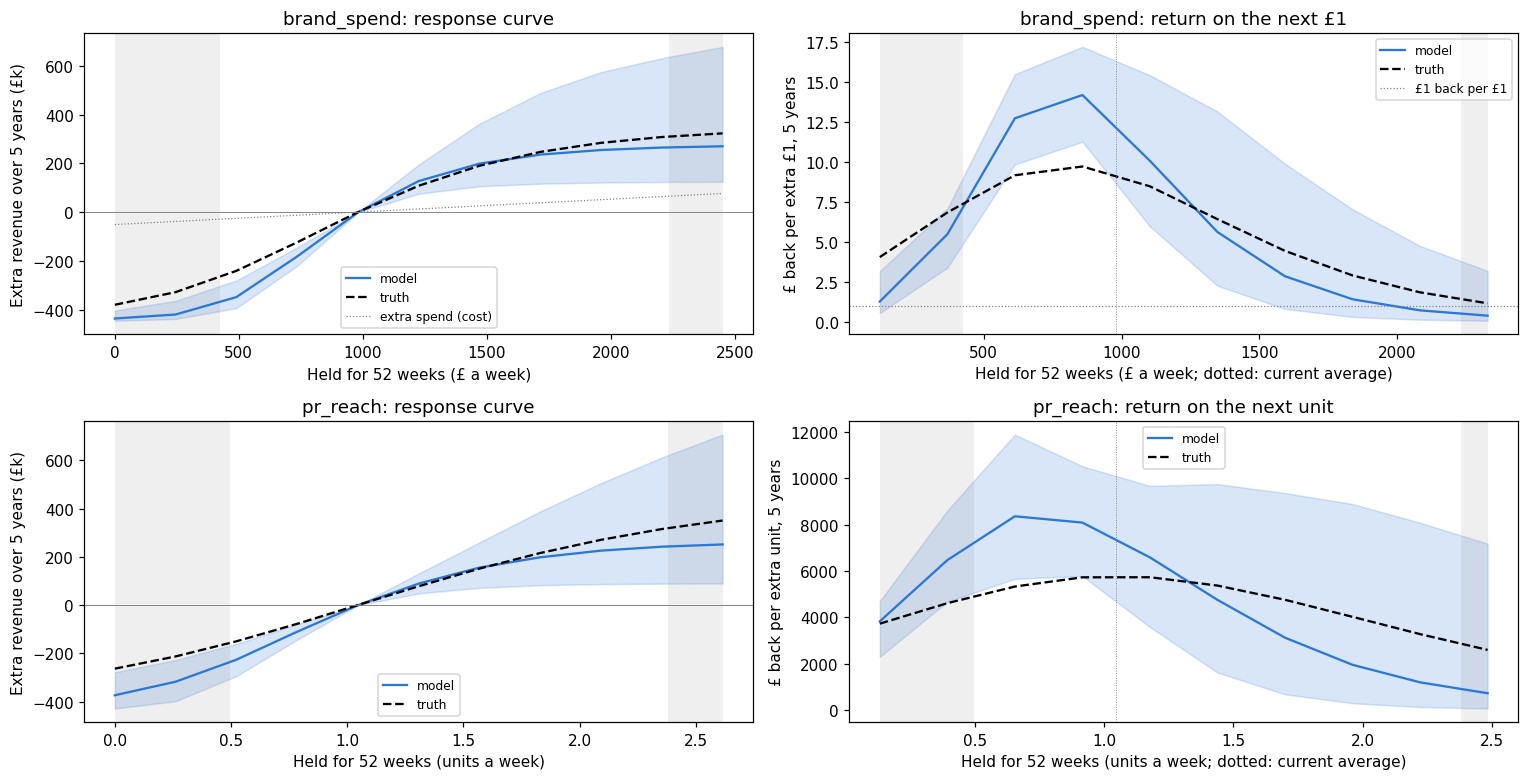

In [14]:
fig, axes = plt.subplots(len(CLEAR), 2, figsize=(14, 3.6 * len(CLEAR)), squeeze=False)
for row, ch in enumerate(CLEAR):
    cost = CHANNELS[ch] or 1.0
    unit = "£" if CHANNELS[ch] else "units"
    weekly = MULTIPLES * spend_mean[ch] * cost
    annual = (MULTIPLES - 1) * spend_mean[ch] * PLAN_WEEKS * cost
    lo_data, hi_data = raw[ch].min() * cost, raw[ch].max() * cost

    ax = axes[row, 0]
    lo, hi = np.percentile(curves[ch], TAILS, axis=1)
    ax.fill_between(weekly, lo / 1e3, hi / 1e3, color="#2a78d6", alpha=0.18)
    ax.plot(weekly, np.median(curves[ch], axis=1) / 1e3, color="#2a78d6", label="model")
    if ch in true_curves:
        ax.plot(weekly, true_curves[ch] / 1e3, color="black", ls="--", label="truth")
    if CHANNELS[ch]:
        ax.plot(weekly, annual / 1e3, color="grey", lw=0.8, ls=":", label="extra spend (cost)")
    ax.axvspan(weekly[0], lo_data, color="grey", alpha=0.12, lw=0)
    ax.axvspan(hi_data, weekly[-1], color="grey", alpha=0.12, lw=0)
    ax.axhline(0, color="grey", lw=0.6)
    ax.set_title(f"{ch}: response curve")
    ax.set_xlabel(f"Held for 52 weeks ({unit} a week)")
    ax.set_ylabel("Extra revenue over 5 years (£k)")
    ax.legend(fontsize=8)

    ax = axes[row, 1]
    mid = (weekly[1:] + weekly[:-1]) / 2
    step = np.diff(annual)
    marginal = np.diff(curves[ch], axis=0) / step[:, None]
    lo, hi = np.percentile(marginal, TAILS, axis=1)
    ax.fill_between(mid, lo, hi, color="#2a78d6", alpha=0.18)
    ax.plot(mid, np.median(marginal, axis=1), color="#2a78d6", label="model")
    if ch in true_curves:
        ax.plot(mid, np.diff(true_curves[ch]) / step, color="black", ls="--", label="truth")
    if CHANNELS[ch]:
        ax.axhline(1, color="grey", lw=0.8, ls=":", label="£1 back per £1")
    ax.axvline(spend_mean[ch] * cost, color="grey", lw=0.6, ls=":")
    ax.axvspan(mid[0], lo_data, color="grey", alpha=0.12, lw=0)
    ax.axvspan(hi_data, mid[-1], color="grey", alpha=0.12, lw=0)
    ax.set_title(f"{ch}: return on the next {'£1' if CHANNELS[ch] else 'unit'}")
    ax.set_xlabel(f"Held for 52 weeks ({unit} a week; dotted: current average)")
    ax.set_ylabel(f"£ back per extra {'£1' if CHANNELS[ch] else 'unit'}, 5 years")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [15]:
rows = []
for ch in CLEAR:
    cost = CHANNELS[ch] or 1.0
    for k in (0.0, 0.5, 1.5, 2.0):
        i = int(np.argmin(np.abs(MULTIPLES - k)))
        level = MULTIPLES[i] * spend_mean[ch]
        inside = raw[ch].min() <= level <= raw[ch].max()
        row = {
            "channel": ch,
            "plan": f"x{k:g} of average",
            "a week": f"£{level * cost:,.0f}" if CHANNELS[ch] else f"{level:.2f} units",
            "extra revenue, 5 years": interval(curves[ch][i], "£{:,.0f}"),
            "in the data?": "yes" if inside else "no: extrapolation",
        }
        if ch in true_curves:
            row["truth"] = f"£{true_curves[ch][i]:,.0f}"
        rows.append(row)
print("Extra revenue over 5 years from 52 weeks at each level, against average spend")
pd.DataFrame(rows).set_index(["channel", "plan"])

Extra revenue over 5 years from 52 weeks at each level, against average spend


a week              extra revenue, 5 years       in the data?      truth
channel     plan                                                                                         
brand_spend x0 of average            £0  £-436,054 (£-445,204 to £-403,431)  no: extrapolation  £-379,786
            x0.5 of average        £490  £-348,279 (£-393,519 to £-280,272)                yes  £-240,690
            x1.5 of average      £1,471     £198,736 (£105,797 to £362,312)                yes   £189,983
            x2 of average        £1,961     £254,498 (£121,217 to £574,075)                yes   £283,915
pr_reach    x0 of average    0.00 units  £-374,069 (£-429,015 to £-279,049)  no: extrapolation  £-263,899
            x0.5 of average  0.52 units  £-226,633 (£-294,475 to £-161,031)                yes  £-150,424
            x1.5 of average  1.57 units      £155,304 (£71,421 to £259,766)                yes   £151,036
            x2 of average    2.09 units      £225,625 (£86,766 to £505,677)                yes   £270,474

**On the simulated data (the default run).** Near current spend the brand spend and PR curves sit on the truth. They overstate the loss from cuts on this data set: halving brand spend comes out at about £348,000 against a true £241,000. Across 10 simulated data sets the same model was within 13% of the truth at every level (guide 05), so this data set is on the unlucky side. Sponsorship has the smallest true effect and the model does not find it here, so its curve is not drawn. With your own data there is no truth line, which is why the intervals and the grey bands matter.

## §6 The checks and the decision log

**Objective:** keep a record of every check and choice for the write-up.

Every row marked **DECIDE** needs your judgement, written down before you look at the returns. Rows marked **LOOK** point to a fix in the agent skill's `reference/diagnostics.md` or `reference/pitfalls.md`.

In [16]:
checks = pd.DataFrame(CHECKS)
print(checks.to_string(index=False))

log = [
    "# Decision log",
    "",
    f"- Data: {'simulated' if SIMULATED else DATA_PATH}, "
    f"{endog.index[0].date()} to {endog.index[-1].date()}, {len(endog)} weeks.",
    f"- Sales: `{SALES}`. Brand metrics: {', '.join(f'`{m}`' for m in BRAND_METRICS)}.",
    f"- Channels: {', '.join(f'`{c}`' for c in channels)}. Other drivers: "
    f"{', '.join(f'`{c}`' for c in OTHER_DRIVERS) or 'none'}.",
    f"- Adstock: {ADSTOCK or 'none'}. Saturation: {SATURATION or 'none'}.",
    f"- Same-week links used: {LINKS_USED or 'none'}. Exclusions: {EXCLUDED_USED or 'none'}.",
    f"- Lags {k_ar_diff}, rank {coint_rank}, deterministic 'co', seed {SEED}, "
    f"{CHAINS} chains x {DRAWS} draws.",
    "",
    "| step | check | result | status | action |",
    "|---|---|---|---|---|",
    *[
        f"| {c['step']} | {c['check']} | {c['result']} | {c['status']} | {c['action']} |"
        for c in CHECKS
    ],
]
if not SIMULATED:
    Path("decision_log.md").write_text("\n".join(log) + "\n")
    model.idata_.to_netcdf("fit.nc")
    print("\nSaved decision_log.md and fit.nc next to this notebook.")

      step                                            check                                            result status                                                                             action
      data                                    weeks of data                                         260 weeks     ok                                                                                   
      data                                   missing values                                                 0     ok                                                                                   
before fit                             organic_sales trends                                               yes     ok                                                                                   
before fit                           brand_awareness trends                                               yes     ok                                                                                   


## How far to trust the answers

- **Only the long-run return is robust to how base sales were built.** Adjustment speeds and half-lives depend on it (guides 06 and 07).
- **The curve for one channel holds the others at average.** Channels flighted together are hard to separate. Plan changes to one channel at a time where you can.
- **Outside the grey bands the curve is an assumption.** A switch-off or a doubling beyond any week in the data is a guess at the shape. Report its interval, not a single number.
- **Exclusions are business assumptions.** The same-week link rests on them, and the data can catch only some wrong ones.
- **Prediction is not proof of cause.** The evidence scores say what helps predict what, under the assumptions in the decision log.
- **Rerun before reporting** with `FINAL_RUN = True`, and quote numbers from the saved `fit.nc`. The sampler is not bit-for-bit reproducible.